# Composite plots da `plots/`

In [1]:
from pathlib import Path
import re

import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from PIL import Image

PLOTS_DIR = Path("plots")
OUT_DIR = PLOTS_DIR
OUT_DIR.mkdir(parents=True, exist_ok=True)

DPI = 300
LEGEND_FONTSIZE = 20
TITLE_FONTSIZE = 20
TITLE_FONTWEIGHT = "bold"
CLUSTER_LEGEND_MARKERSIZE = 8
CLUSTER_LEGEND_MARKERSCALE = 0.75
CLUSTER_LEGEND_OUTSIDE_OFFSET = 0.025

plt.rcParams.update({
    "font.size": 20,
    "axes.titlesize": 20,
    "axes.labelsize": 20,
    "xtick.labelsize": 20,
    "ytick.labelsize": 20,
    "legend.fontsize": LEGEND_FONTSIZE,
    "legend.title_fontsize": LEGEND_FONTSIZE,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
})

## Colors and labels

In [2]:
TASK_CLUSTER_COLORS = [
    "#6F5FA7",
    "#B08A2E",
    "#99C0D7",
    "#356587",
    "#5B8C3B",
    "#2F7E7A",
]

TASK_ID_TO_NAME = {
    0: "TS6: Normalization",
    1: "TS2: Detoxify language",
    2: "TS1: Positive tone",
    3: "TS4: Polite style",
    4: "TS5: Virginia Woolf style",
    5: "TS3: Objective style",
}

CLUSTER_LEGEND_ORDER = [2, 1, 5, 3, 4, 0]

OUTLIER_COLOR = "#2E2A2F"
OUTLIER_LABEL = "ALPACA"

RHO_COLORS = ["#6F5FA7", "#B08A2E", "#99C0D7", "#356587", "#5B8C3B"]

## Helper

In [3]:
MODEL_LABELS = {
    "llama_3_2": "Llama 3.2",
    "olmo_2": "OLMo 2",
    "qwen_2_5": "Qwen 2.5",
}


def natural_key(x):
    s = str(x)
    return [int(t) if t.isdigit() else t.lower() for t in re.split(r"(\d+)", s)]


def model_key_from_path(path: Path) -> str:
    stem = path.stem
    for suffix in ("_accuracy_vs_rho", "_best_layers", "_clustering"):
        if stem.endswith(suffix):
            return stem[: -len(suffix)]
    return stem


def pretty_model_label(path: Path) -> str:
    key = model_key_from_path(path)
    return MODEL_LABELS.get(key, key.replace("_", " ").title())


def find_plot_files(kind: str, include_llama: bool = True):
    suffix = kind
    files = sorted(PLOTS_DIR.glob(f"*_{suffix}.png"), key=natural_key)
    if not include_llama:
        files = [p for p in files if not model_key_from_path(p).startswith("llama")]

    if not files:
        raise FileNotFoundError(
            f"Nessun file trovato per kind={kind!r}, include_llama={include_llama}. "
            f"Controlla che esistano PNG in {PLOTS_DIR.resolve()}"
        )
    return files


def read_png(path: Path, crop_right_fraction: float = 0.0, crop_left_fraction: float = 0.0):
    img = Image.open(path).convert("RGBA")
    w, h = img.size
    left = int(w * crop_left_fraction)
    right = int(w * (1.0 - crop_right_fraction))
    return img.crop((left, 0, right, h))


def show_image_on_ax(ax, path: Path, title: str | None = None, **read_kwargs):
    img = read_png(path, **read_kwargs)
    ax.imshow(img)
    ax.axis("off")
    if title:
        ax.set_title(
            title,
            fontsize=TITLE_FONTSIZE,
            fontweight=TITLE_FONTWEIGHT,
            pad=20,
        )


def cluster_legend_handles():
    handles = []
    for tid in CLUSTER_LEGEND_ORDER:
        handles.append(
            Line2D(
                [0], [0],
                marker="o",
                linestyle="None",
                markersize=CLUSTER_LEGEND_MARKERSIZE,
                markerfacecolor=TASK_CLUSTER_COLORS[tid],
                markeredgecolor="white",
                markeredgewidth=0.8,
                label=TASK_ID_TO_NAME[tid],
            )
        )

    handles.append(
        Line2D(
            [0], [0],
            marker="o",
            linestyle="None",
            markersize=CLUSTER_LEGEND_MARKERSIZE,
            markerfacecolor=OUTLIER_COLOR,
            markeredgecolor=OUTLIER_COLOR,
            label=OUTLIER_LABEL,
        )
    )
    return handles


def rho_legend_handles():
    return [
        Line2D(
            [0], [0],
            marker="o",
            color=RHO_COLORS[1],
            markerfacecolor=RHO_COLORS[1],
            markeredgecolor=RHO_COLORS[1],
            label="Selection accuracy (in-domain)",
        ),
        Line2D(
            [0], [0],
            linestyle="--",
            color=RHO_COLORS[2],
            linewidth=2.2,
            label="Refusal (OOD)",
        ),
    ]


def save_and_show(fig, out_path: Path):
    fig.savefig(out_path, dpi=DPI, bbox_inches="tight", facecolor="white")
    print(f"Salvato: {out_path}")
    plt.show()

## Clustering

Salvato: plots\combined_clustering_non_llama.png


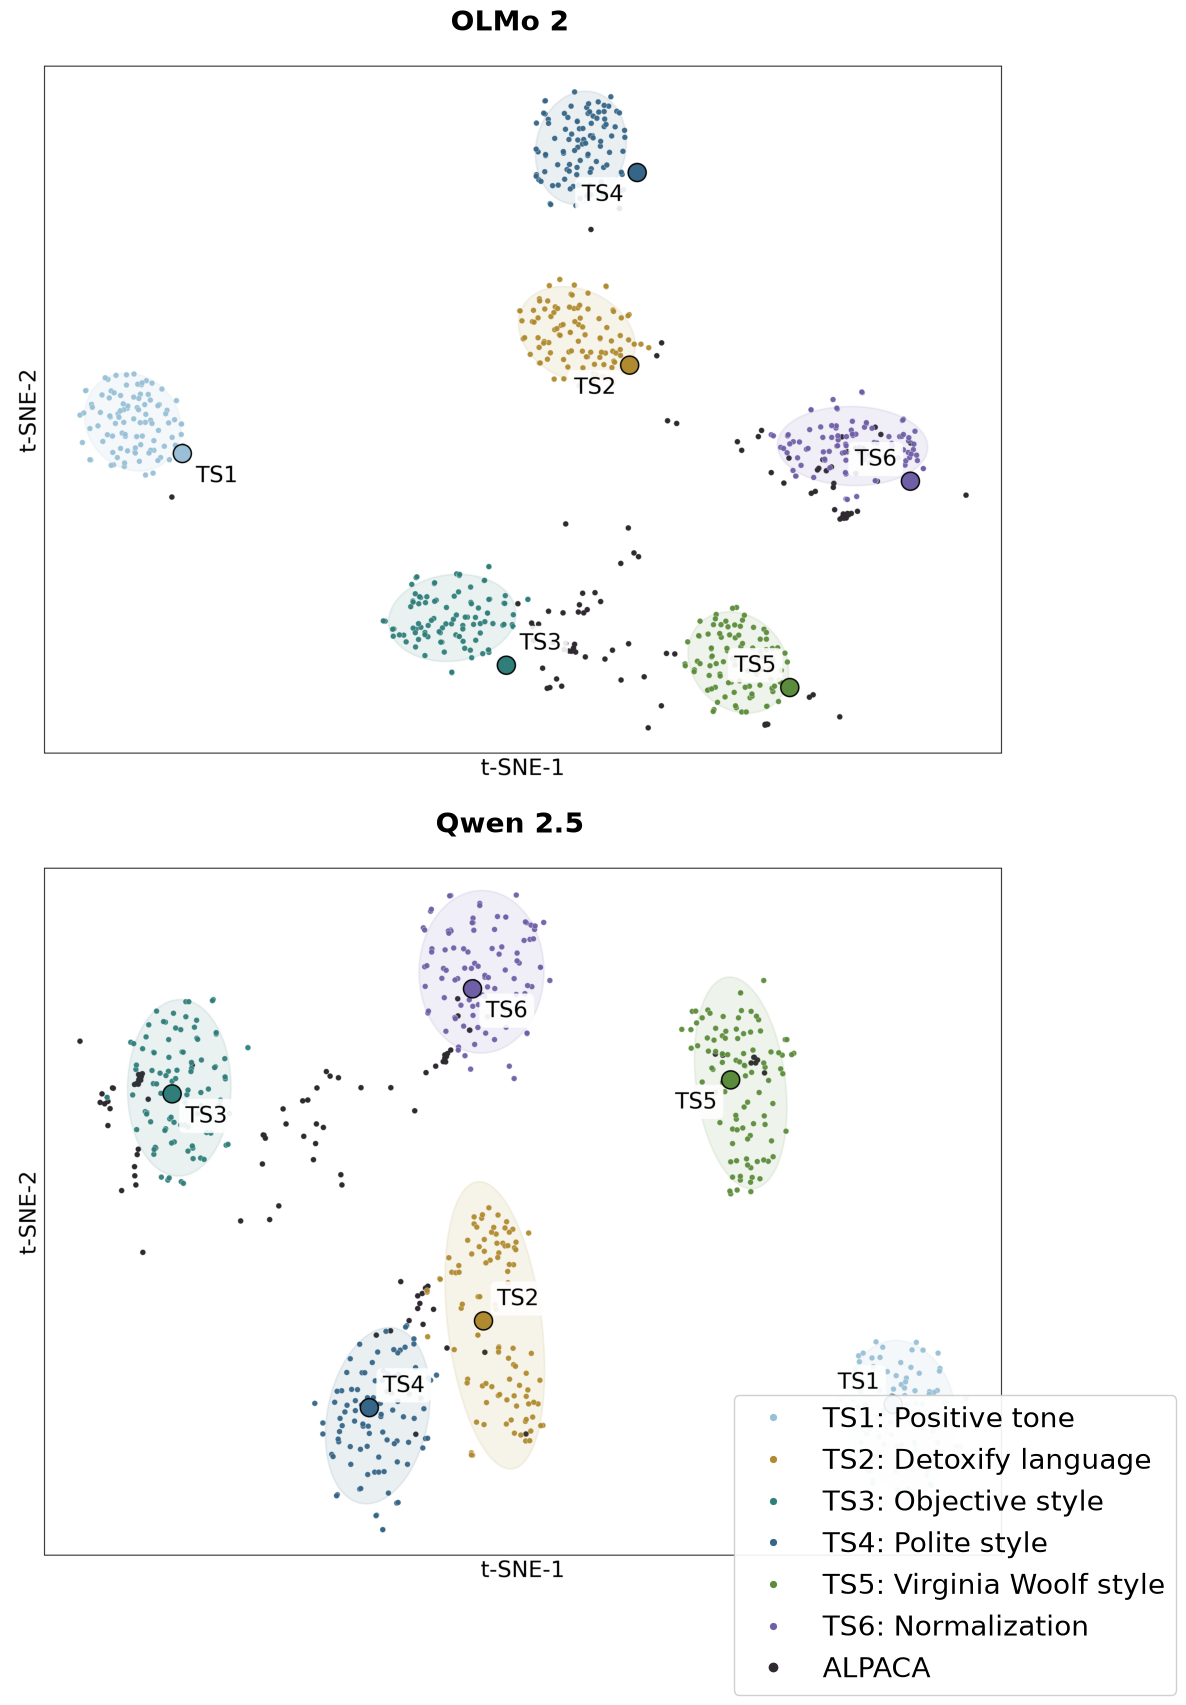

In [4]:
def make_combined_clustering_non_llama(
    files=None,
    out_path: Path = OUT_DIR / "combined_clustering_non_llama.png",
    crop_right_fraction: float = 0.0,
):
    files = files or find_plot_files("clustering", include_llama=False)
    n = len(files)

    fig, axes = plt.subplots(n, 1, figsize=(15.5, 8.8 * n), squeeze=False)
    axes = axes.ravel()

    for ax, path in zip(axes, files):
        show_image_on_ax(
            ax,
            path,
            title=pretty_model_label(path),
            crop_right_fraction=crop_right_fraction,
        )

    handles = cluster_legend_handles()
    labels = [h.get_label() for h in handles]

    fig.legend(
        handles,
        labels,
        loc="lower right",
        bbox_to_anchor=(
            0.84,0.04
        ),
        bbox_transform=fig.transFigure,
        title=None,
        frameon=True,
        framealpha=0.92,
        borderaxespad=0.0,
        fontsize=LEGEND_FONTSIZE,
        markerscale=CLUSTER_LEGEND_MARKERSCALE,
    )

    fig.subplots_adjust(left=0.02, right=0.80, top=0.97, bottom=0.10, hspace=0.10)
    save_and_show(fig, out_path)


make_combined_clustering_non_llama()

## Best layers

Salvato: plots\combined_best_layers.png


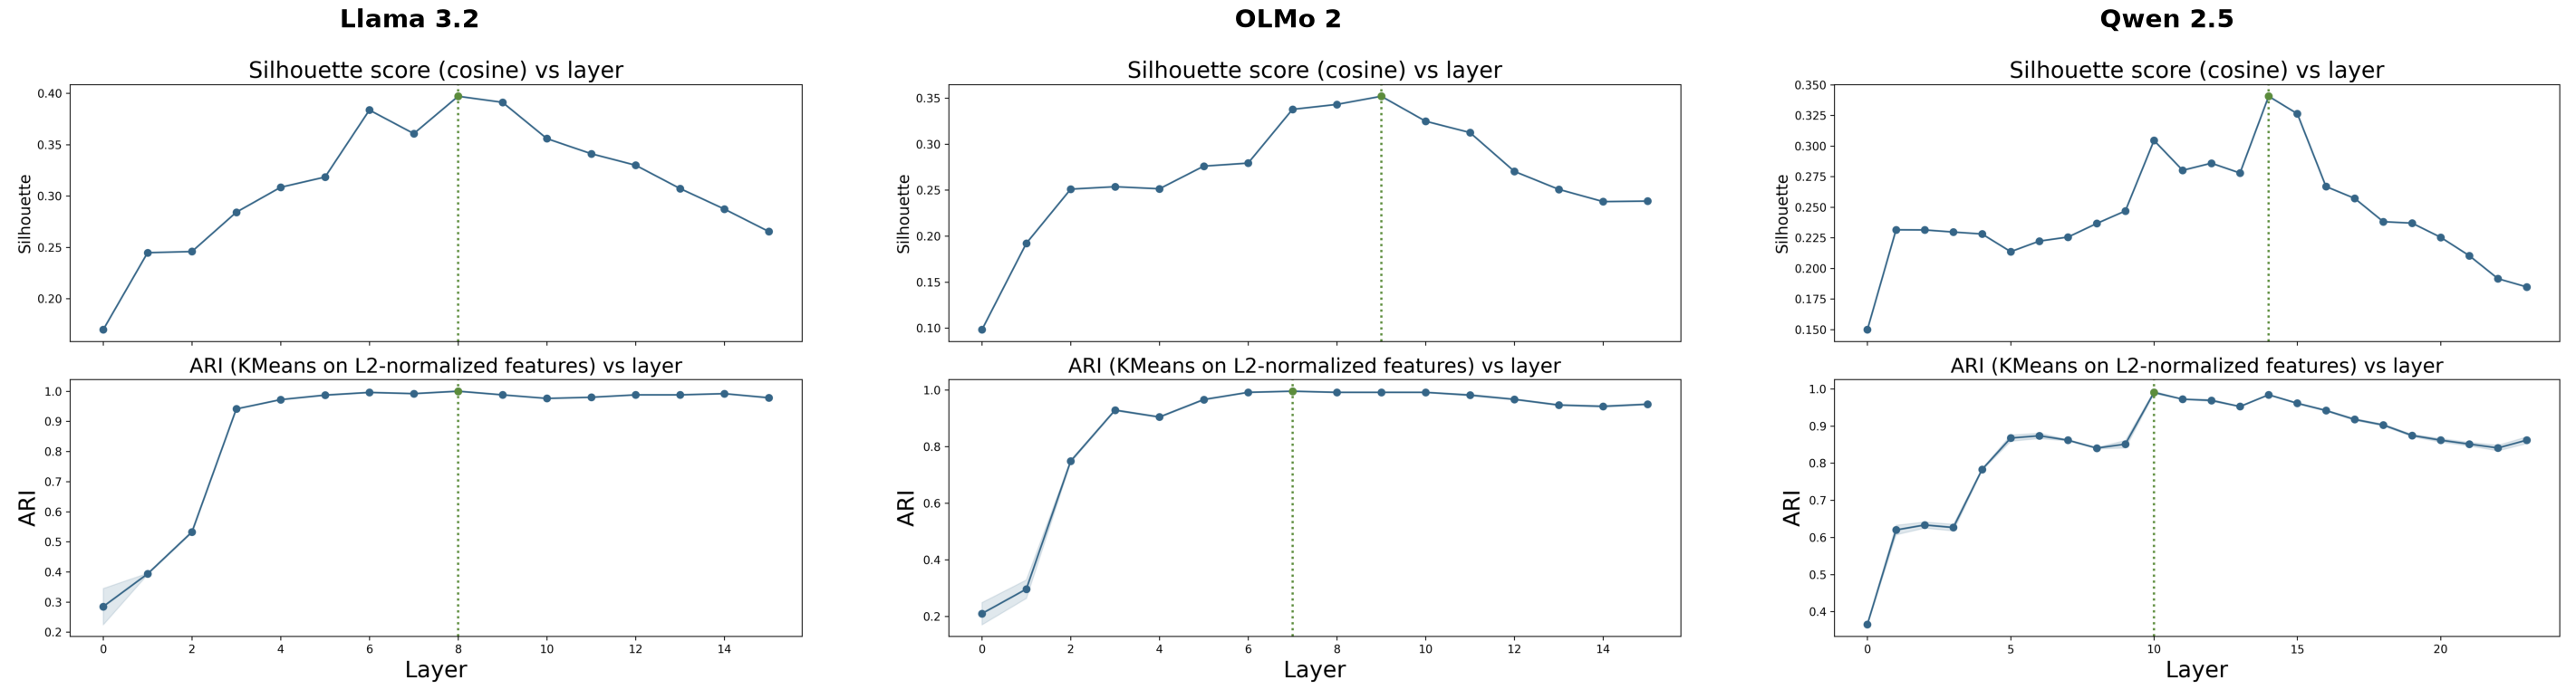

In [5]:
def make_combined_best_layers(
    files=None,
    out_path: Path = OUT_DIR / "combined_best_layers.png",
):
    files = files or find_plot_files("best_layers", include_llama=True)
    n = len(files)

    fig, axes = plt.subplots(1, n, figsize=(9.8 * n, 8.0), squeeze=False)
    axes = axes.ravel()

    for ax, path in zip(axes, files):
        show_image_on_ax(ax, path, title=pretty_model_label(path))

    fig.subplots_adjust(left=0.01, right=0.99, top=0.90, bottom=0.02, wspace=0.03)
    save_and_show(fig, out_path)


make_combined_best_layers()

## 'accuracy_vs_rho'

Salvato: plots\combined_accuracy_vs_rho.png


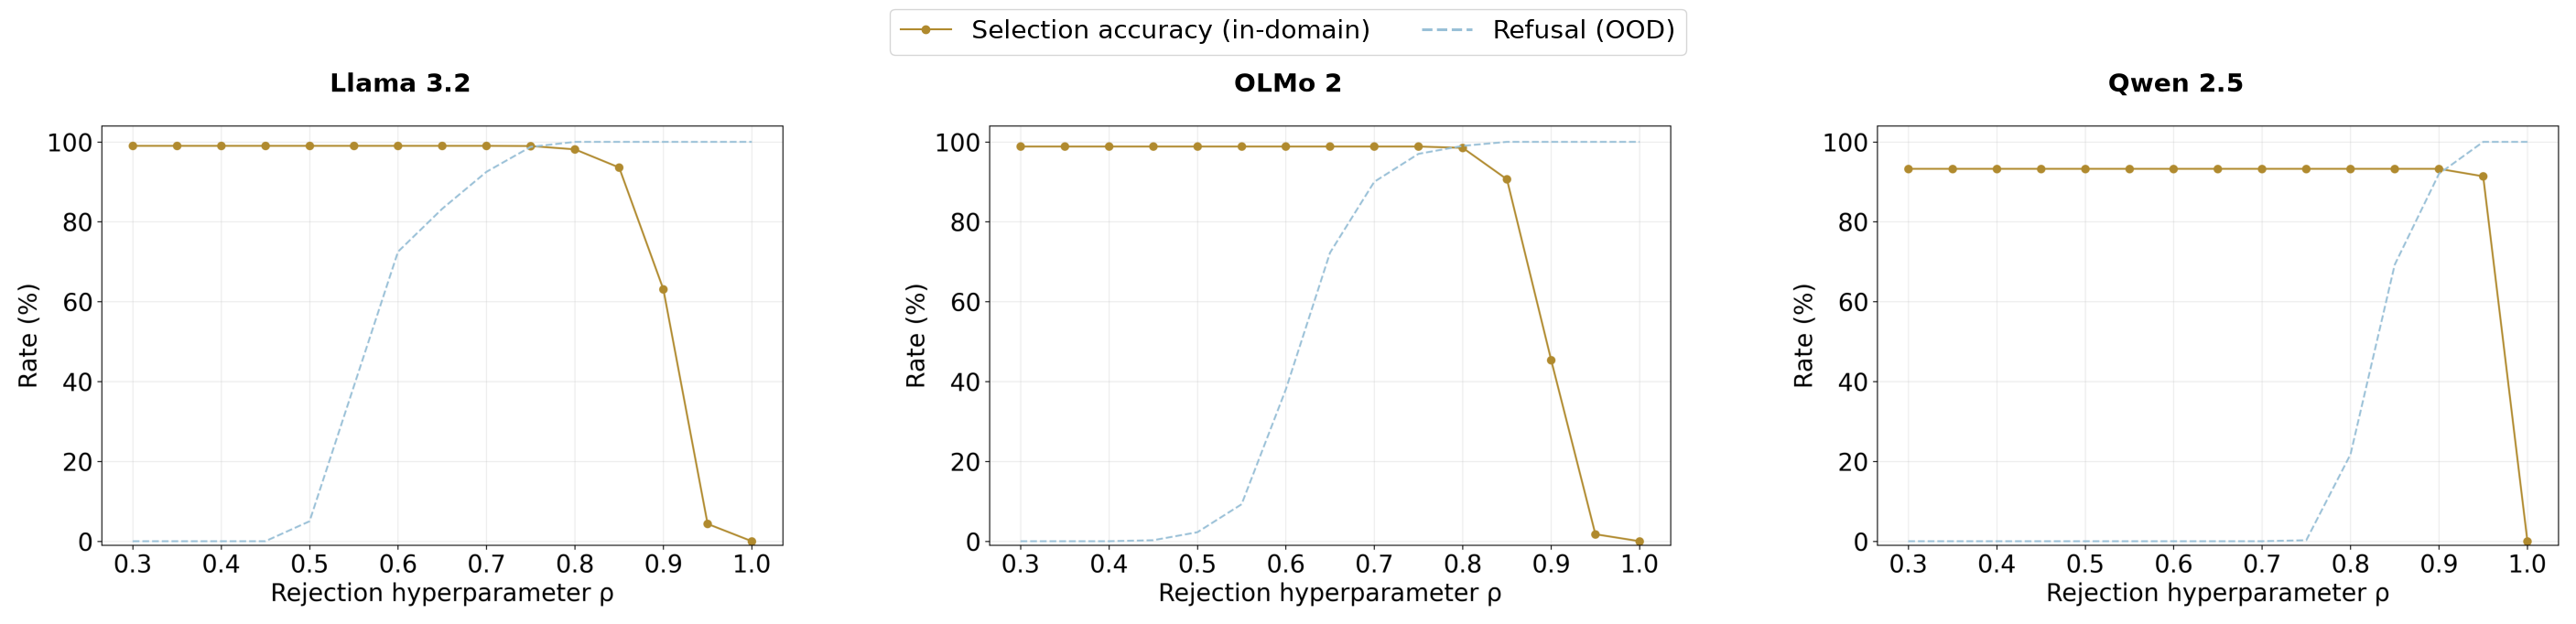

In [6]:
def make_combined_accuracy_vs_rho(
    files=None,
    out_path: Path = OUT_DIR / "combined_accuracy_vs_rho.png",
):
    files = files or find_plot_files("accuracy_vs_rho", include_llama=True)
    n = len(files)

    fig, axes = plt.subplots(1, n, figsize=(9.8 * n, 6.8), squeeze=False)
    axes = axes.ravel()

    for ax, path in zip(axes, files):
        show_image_on_ax(ax, path, title=pretty_model_label(path))
    handles = rho_legend_handles()
    labels = [h.get_label() for h in handles]

    fig.legend(
        handles,
        labels,
        loc="lower center",
        bbox_to_anchor=(0.5, 0.9),
        ncol=2,
        frameon=True,
        fontsize=LEGEND_FONTSIZE,
    )

    fig.subplots_adjust(left=0.01, right=0.99, top=0.82, bottom=0.02, wspace=0.03)
    save_and_show(fig, out_path)


make_combined_accuracy_vs_rho()